# Pertemuan 7 — Praktikum 1: Regresi Linier

Praktikum ini menerapkan regresi linier sederhana pada dataset pelanggan sebuah toko daring. Tujuan praktikum adalah memahami karakteristik data, memilih variabel bebas berdasarkan analisis korelasi, melatih model regresi linier dengan library StatsModels, menganalisis residual, dan mengukur kinerja model pada data uji dengan nilai R-squared.

Setiap sel dijalankan berurutan dari atas ke bawah, dimulai dari pemuatan data hingga visualisasi hasil prediksi.

Sumber: [Praktikum 1](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-regresi/praktikum1).

## 1. Import library

Sel berikut memuat pustaka NumPy dan Pandas yang dipakai untuk manipulasi data.

In [1]:
%matplotlib inline

# import package
import numpy as np
import pandas as pd

## 2. Membaca data

Data dibaca dari berkas `dataset.csv` yang berada pada direktori yang sama. Berkas ini memuat data pelanggan toko daring dengan delapan kolom, yaitu identitas pelanggan dan lima variabel perilaku belanja.

In [2]:
# baca data dari file CSV
data = pd.read_csv('dataset.csv')

# melihat beberapa data awal
display(data.head())

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


## 3. Pemahaman terhadap data

Ukuran data, tipe setiap kolom, serta ringkasan statistik ditampilkan untuk mengenali karakteristik data. Langkah ini penting agar pemilihan variabel dan penanganan data dilakukan dengan tepat.

In [3]:
# mengecek ukuran data
print("Ukuran data:", data.shape)
print()

# informasi tentang data
print("Informasi data:")
data.info()
print()

# deskripsi data
print("Deskripsi statistik:")
display(data.describe().round(2))

Ukuran data: (500, 8)

Informasi data:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 31.4 KB

Deskripsi statistik:


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.00,500.00,500.00,500.00,500.00
mean,33.05,12.05,37.06,3.53,499.31
std,0.99,0.99,1.01,1.00,79.31
min,29.53,8.51,33.91,0.27,256.67
25%,32.34,11.39,36.35,2.93,445.04
50%,33.08,11.98,37.07,3.53,498.89
75%,33.71,12.75,37.72,4.13,549.31
max,36.14,15.13,40.01,6.92,765.52


## 4. Visualisasi data

Hubungan antara setiap variabel bebas dan variabel target digambarkan dengan pairplot dalam bentuk scatter plot. Matplotlib dan Seaborn dipakai sebagai pustaka visualisasi.

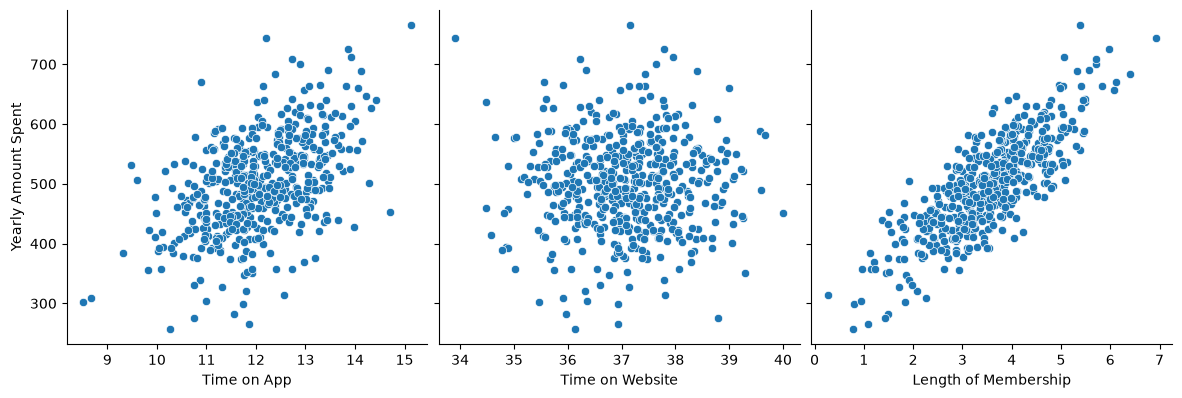

In [4]:
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# visualisasi data dengan pairplot
sns.pairplot(data,
             x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', height=4, aspect=1, kind='scatter')
plt.show()

Pairplot belum cukup jelas menunjukkan kekuatan hubungan setiap variabel bebas terhadap variabel target. Matriks korelasi ditampilkan dengan heatmap agar nilai korelasi antar variabel dapat dibandingkan secara langsung. Kolom non-numerik disaring lebih dahulu karena korelasi hanya berlaku untuk data numerik.

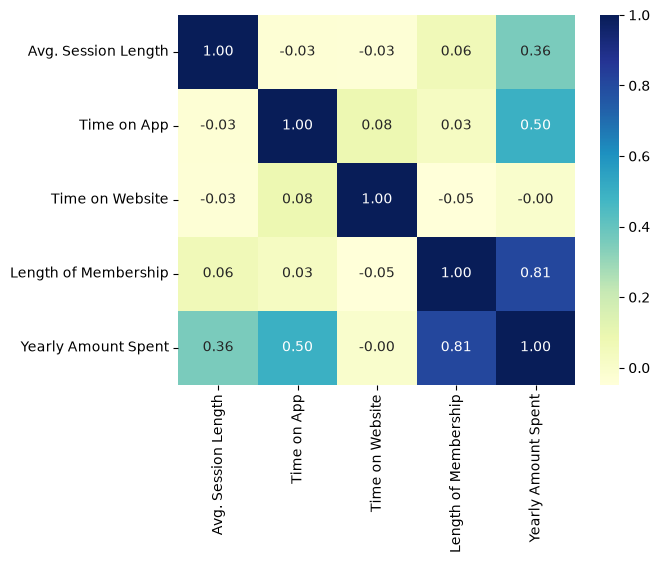

In [5]:
# visualisasi korelasi dengan heatmap
kolom_numerik = data.select_dtypes(include='number')

sns.heatmap(kolom_numerik.corr(), cmap="YlGnBu", annot=True, fmt=".2f")
plt.show()

Nilai korelasi menunjukkan bahwa `Length of Membership` memiliki hubungan paling kuat terhadap `Yearly Amount Spent`, sehingga variabel tersebut dipilih sebagai variabel bebas pada model regresi linier sederhana.

## 5. Membentuk variabel bebas dan target

Variabel bebas (X) diisi oleh `Length of Membership`, sedangkan variabel target (y) diisi oleh `Yearly Amount Spent`.

In [6]:
# Buat variabel bebas X dan Y dari hasil analisis korelasi
X = data['Length of Membership']
y = data['Yearly Amount Spent']

display(X.head())

0    4.082621
1    2.664034
2    4.104543
3    3.120179
4    4.446308
Name: Length of Membership, dtype: float64

## 6. Pembagian data latih dan data uji

Data dibagi menjadi data latih sebesar 70% dan data uji sebesar 30%. Nilai `random_state` ditetapkan agar pembagian data dapat diulang dengan hasil yang sama.

In [7]:
# Pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7,
                                                    test_size=0.3, random_state=100)

## 7. Pelatihan model regresi linier

Model regresi linier dilatih dengan library StatsModels. Konstanta (intercept) ditambahkan ke variabel bebas melalui `add_constant`, kemudian model diestimasi dengan metode kuadrat terkecil (`OLS`). Nilai parameter dan ringkasan statistik model ditampilkan untuk melihat kecocokan garis regresi terhadap data latih.

In [8]:
# Training model
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

print("Parameter model:")
display(lr.params)
print(f"R-squared data latih: {lr.rsquared:.4f}")

Parameter model:


const                   265.248299
Length of Membership     66.301522
dtype: float64

R-squared data latih: 0.6688


In [9]:
# analisis statistika dari garis regresi
lr.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                             OLS Regression Results                            
===============================================================================
Dep. Variable:     Yearly Amount Spent   R-squared:                       0.669
Model:                             OLS   Adj. R-squared:                  0.668
Method:                  Least Squares   F-statistic:                     702.9
Date:                 Mon, 12 Oct 2026   Prob (F-statistic):           1.59e-85
Time:                         16:15:55   Log-Likelihood:                -1841.3
No. Observations:                  350   AIC:                             3687.
Df Residuals:                      348   BIC:                             3694.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                  265.2483      9.120     29.083      0.000     247.311     283.186
Length of Membership    66.3015      2.501     26.512      0.000      61.383      71.220
==============================================================================
Omnibus:                        1.643   Durbin-Watson:                   1.929
Prob(Omnibus):                  0.440   Jarque-Bera (JB):                1.471
Skew:                          -0.013   Prob(JB):                        0.479
Kurtosis:                       2.683   Cond. No.                         14.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## 8. Visualisasi garis regresi

Garis regresi digambarkan bersama titik-titik data latih. Garis merah merupakan model yang dihasilkan, dengan intercept dan kemiringan sesuai parameter yang telah diestimasi.

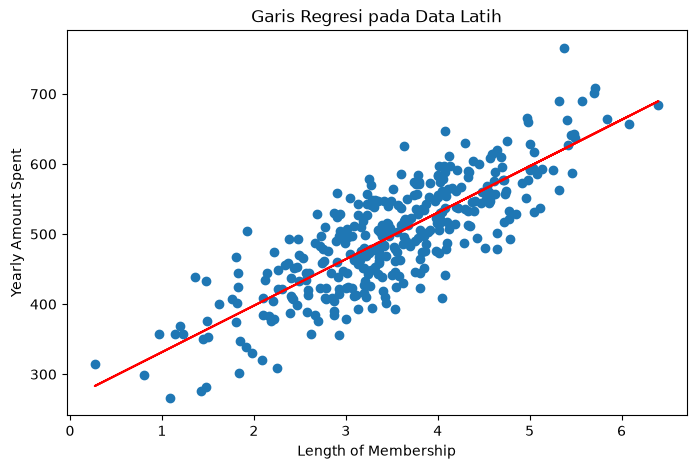

Persamaan garis: Yearly Amount Spent = 265.2483 + 66.3015 * Length of Membership


In [10]:
# visualisasi garis regresi
const = lr.params['const']
slope = lr.params['Length of Membership']

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train)
plt.plot(X_train, const + slope * X_train, 'r')
plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.title('Garis Regresi pada Data Latih')
plt.show()

print(f"Persamaan garis: Yearly Amount Spent = {const:.4f} + {slope:.4f} * Length of Membership")

## 9. Analisis residual

Residual adalah selisih antara nilai sebenarnya dan nilai prediksi pada data latih. Histogram residual dipakai untuk melihat apakah residual menyebar mendekati normal, sedangkan scatter plot residual terhadap variabel bebas dipakai untuk melihat apakah masih terdapat pola yang belum tertangkap model.

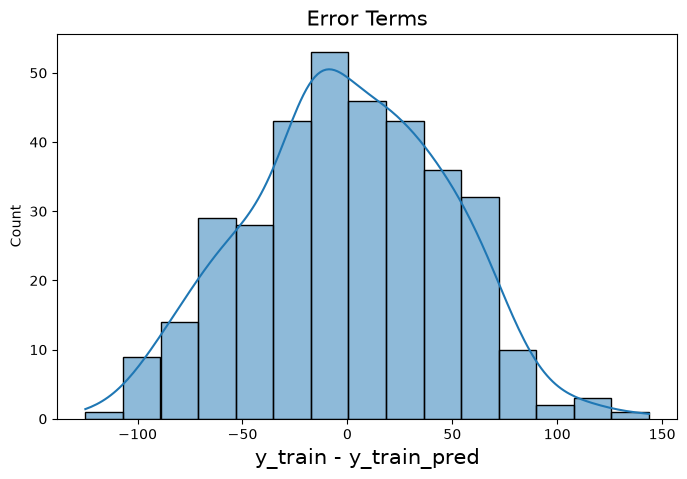

In [11]:
# prediksi y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

# menghitung residual
res = (y_train - y_train_pred)

# histogram residual
plt.figure(figsize=(8, 5))
sns.histplot(res, bins=15, kde=True)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

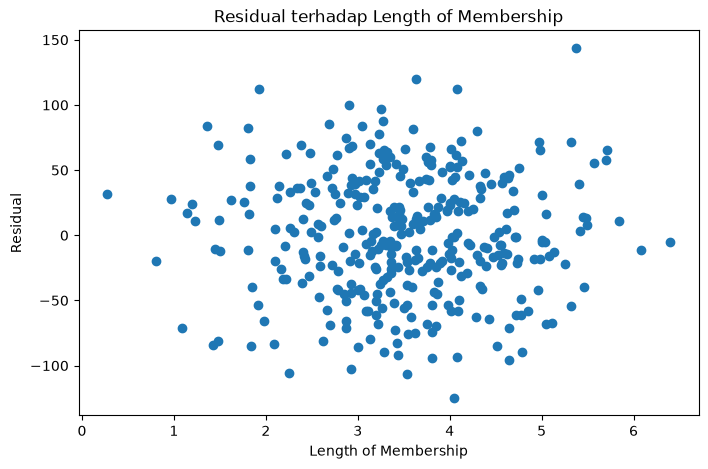

In [12]:
# scatter plot residual
plt.figure(figsize=(8, 5))
plt.scatter(X_train, res)
plt.xlabel('Length of Membership')
plt.ylabel('Residual')
plt.title('Residual terhadap Length of Membership')
plt.show()

## 10. Prediksi pada data uji dan evaluasi model

Model yang telah dilatih dipakai untuk memprediksi data uji. Nilai R-squared dihitung untuk mengukur seberapa besar keragaman `Yearly Amount Spent` yang dapat dijelaskan model pada data yang belum pernah dilihat.

In [13]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

print("Contoh hasil prediksi pada data uji:")
display(y_test_pred.head())

# Hitung nilai R-squared
from sklearn.metrics import r2_score

r_squared = r2_score(y_test, y_test_pred)
print(f"R-squared data uji: {r_squared:.4f}")

Contoh hasil prediksi pada data uji:


69     500.794385
29     579.688406
471    533.188991
344    446.066436
54     455.838449
dtype: float64

R-squared data uji: 0.6119


## 11. Visualisasi hasil prediksi

Data uji dan hasil prediksi digambarkan dalam satu bidang agar kesesuaian model dengan data sebenarnya dapat dilihat secara visual.

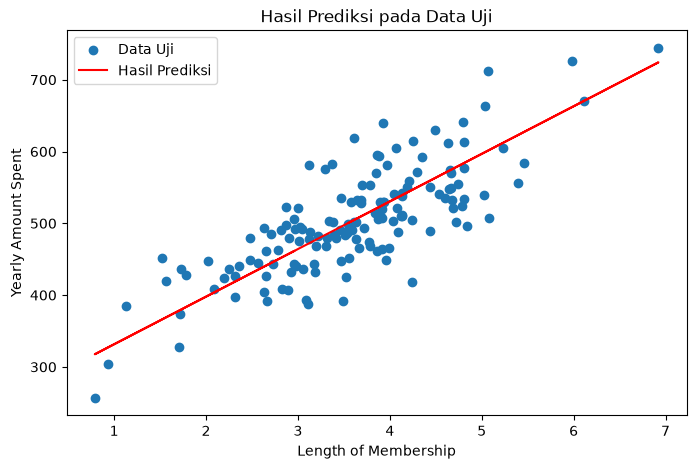

In [14]:
# Visualisasi data uji dan hasil prediksi
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, label='Data Uji')
plt.plot(X_test, y_test_pred, 'r', label='Hasil Prediksi')
plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.title('Hasil Prediksi pada Data Uji')
plt.legend()
plt.show()

## Kesimpulan

Regresi linier sederhana berhasil memodelkan hubungan antara `Length of Membership` dan `Yearly Amount Spent`. Nilai parameter yang diperoleh adalah intercept 265,2483 dan kemiringan 66,3015, sehingga setiap penambahan satu satuan lama keanggotaan menaikkan pengeluaran tahunan sekitar 66,3 dolar. Nilai R-squared data latih sebesar 0,6688 dan data uji sebesar 0,6119. Kedua nilai tersebut tidak berbeda jauh, sehingga model dinilai cukup stabil dan tidak mengalami overfitting yang berarti.